# Exploratory Data Analysis: AI4I 2020 Predictive Maintenance

Goal: understand the sensor data and how machine failures differ from normal operation.
The dataset is synthetic (simulated industrial data), so findings describe this dataset only.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

# The notebook lives in notebooks/, so the data path starts with ../
df = pd.read_csv("../data/ai4i2020.csv")
df = df.rename(columns={
    "Air temperature [K]": "air_temp_k",
    "Process temperature [K]": "process_temp_k",
    "Rotational speed [rpm]": "rot_speed_rpm",
    "Torque [Nm]": "torque_nm",
    "Tool wear [min]": "tool_wear_min",
    "Machine failure": "machine_failure",
})

sensor_cols = ["air_temp_k", "process_temp_k", "rot_speed_rpm", "torque_nm", "tool_wear_min"]
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
any_mode = df[modes].sum(axis=1) > 0

print(df.shape)

(10000, 14)


In [2]:
print(df[sensor_cols].describe().round(2).to_string())

       air_temp_k  process_temp_k  rot_speed_rpm  torque_nm  tool_wear_min
count     10000.0        10000.00       10000.00   10000.00       10000.00
mean        300.0          310.01        1538.78      39.99         107.95
std           2.0            1.48         179.28       9.97          63.65
min         295.3          305.70        1168.00       3.80           0.00
25%         298.3          308.80        1423.00      33.20          53.00
50%         300.1          310.10        1503.00      40.10         108.00
75%         301.5          311.10        1612.00      46.80         162.00
max         304.5          313.80        2886.00      76.60         253.00


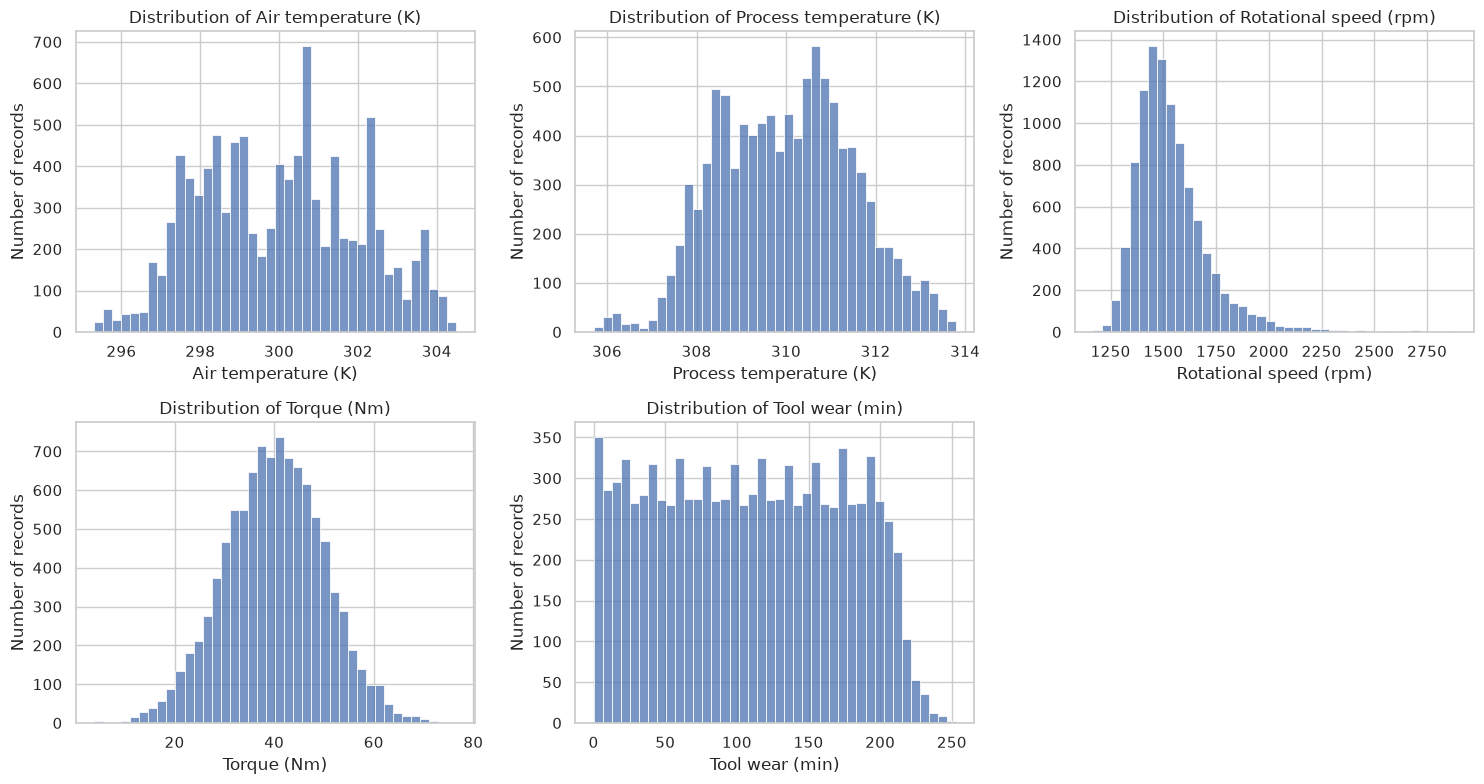

In [3]:
sensor_labels = {
    "air_temp_k": "Air temperature (K)",
    "process_temp_k": "Process temperature (K)",
    "rot_speed_rpm": "Rotational speed (rpm)",
    "torque_nm": "Torque (Nm)",
    "tool_wear_min": "Tool wear (min)",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, (col, label) in zip(axes, sensor_labels.items()):
    sns.histplot(df[col], bins=40, ax=ax)
    ax.set_title(f"Distribution of {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of records")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [4]:
print("Mean sensor values by machine_failure:\n")
print(df.groupby("machine_failure")[sensor_cols].mean().round(2).to_string())

print("\nFailure rate by product Type:\n")
print(
    df.groupby("Type")["machine_failure"]
    .agg(records="count", failures="sum", failure_rate="mean")
    .round(4)
    .to_string()
)

Mean sensor values by machine_failure:

                 air_temp_k  process_temp_k  rot_speed_rpm  torque_nm  tool_wear_min
machine_failure                                                                     
0                    299.97          310.00        1540.26      39.63         106.69
1                    300.89          310.29        1496.49      50.17         143.78

Failure rate by product Type:

      records  failures  failure_rate
Type                                 
H        1003        21        0.0209
L        6000       235        0.0392
M        2997        83        0.0277


          records  failures  failure_rate
wear_bin                                 
0-49         2349        52        0.0221
50-99        2271        51        0.0225
100-149      2290        52        0.0227
150-199      2289        61        0.0266
200-249       799       121        0.1514
250+            2         2        1.0000


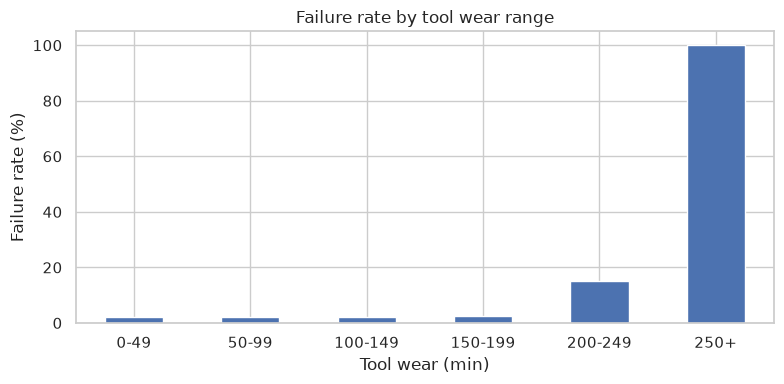

In [5]:
df["wear_bin"] = pd.cut(
    df["tool_wear_min"],
    bins=[0, 50, 100, 150, 200, 250, 300],
    right=False,
    labels=["0-49", "50-99", "100-149", "150-199", "200-249", "250+"],
)

wear_summary = (
    df.groupby("wear_bin", observed=True)["machine_failure"]
    .agg(records="count", failures="sum", failure_rate="mean")
    .round(4)
)
print(wear_summary.to_string())

ax = (wear_summary["failure_rate"] * 100).plot(kind="bar", figsize=(8, 4))
ax.set_title("Failure rate by tool wear range")
ax.set_xlabel("Tool wear (min)")
ax.set_ylabel("Failure rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
print("Records per failure mode:\n")
print(df[modes].sum().to_string())

print("\nmachine_failure vs 'any failure-mode flag':\n")
print(pd.crosstab(df["machine_failure"], any_mode,
                  rownames=["machine_failure"], colnames=["any_mode_flag"]).to_string())

Records per failure mode:

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19

machine_failure vs 'any failure-mode flag':

any_mode_flag    False  True 
machine_failure              
0                 9643     18
1                    9    330


In [7]:
# Case A: some failure mode is flagged, but machine_failure == 0
flag_no_fail = df[(df["machine_failure"] == 0) & any_mode]
print("Flagged mode but machine_failure == 0:", len(flag_no_fail))
print(flag_no_fail[modes].sum().to_string())

# Case B: machine_failure == 1, but no failure mode is flagged
fail_no_flag = df[(df["machine_failure"] == 1) & ~any_mode]
print("\nmachine_failure == 1 but no mode flagged:", len(fail_no_flag))
print(fail_no_flag[["Type"] + sensor_cols].to_string())

Flagged mode but machine_failure == 0: 18
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18

machine_failure == 1 but no mode flagged: 9
     Type  air_temp_k  process_temp_k  rot_speed_rpm  torque_nm  tool_wear_min
1437    H       298.8           309.9           1439       45.2             40
2749    M       299.7           309.2           1685       28.9            179
4044    M       301.9           310.9           1419       47.7             20
4684    M       303.6           311.8           1421       44.8            101
5536    M       302.3           311.8           1363       54.0            119
5941    L       300.6           310.7           1438       48.5             78
6478    L       300.5           309.8           1663       29.1            145
8506    L       298.4           309.6           1710       27.3            163
9015    L       297.2           308.1           1431       49.7            210


In [8]:
# Physics-motivated features (built only from sensor readings, not from failure labels)
df["temp_diff_k"] = df["process_temp_k"] - df["air_temp_k"]
# Power in watts: torque (Nm) x angular speed (rad/s); rpm * 2*pi/60 = rad/s
df["power_w"] = df["torque_nm"] * df["rot_speed_rpm"] * 2 * np.pi / 60
# Overstrain proxy: tool wear x torque (min*Nm)
df["wear_torque"] = df["tool_wear_min"] * df["torque_nm"]

new_feats = ["temp_diff_k", "power_w", "wear_torque"]

print("Overall:\n")
print(df[new_feats].describe().round(2).to_string())

print("\nMean by machine_failure:\n")
print(df.groupby("machine_failure")[new_feats].mean().round(2).to_string())

print("\nThe 9 failures with no failure mode flagged:\n")
print(df.loc[fail_no_flag.index, new_feats].round(1).to_string())

Overall:

       temp_diff_k   power_w  wear_torque
count      10000.0  10000.00     10000.00
mean          10.0   6279.74      4314.66
std            1.0   1067.42      2826.57
min            7.6   1148.44         0.00
25%            9.3   5561.18      1963.65
50%            9.8   6271.03      4012.95
75%           11.0   7003.00      6279.00
max           12.1  10469.92     16497.00

Mean by machine_failure:

                 temp_diff_k  power_w  wear_torque
machine_failure                                   
0                      10.02  6244.55      4213.84
1                       9.40  7282.82      7187.94

The 9 failures with no failure mode flagged:

      temp_diff_k  power_w  wear_torque
1437         11.1   6811.3       1808.0
2749          9.5   5099.5       5173.1
4044          9.0   7088.1        954.0
4684          8.2   6666.5       4524.8
5536          9.5   7707.6       6426.0
5941         10.1   7303.5       3783.0
6478          9.3   5067.7       4219.5
8506         1

Correlation with machine_failure:

torque_nm         0.191
wear_torque       0.190
power_w           0.176
tool_wear_min     0.105
air_temp_k        0.083
process_temp_k    0.036
rot_speed_rpm    -0.044
temp_diff_k      -0.112


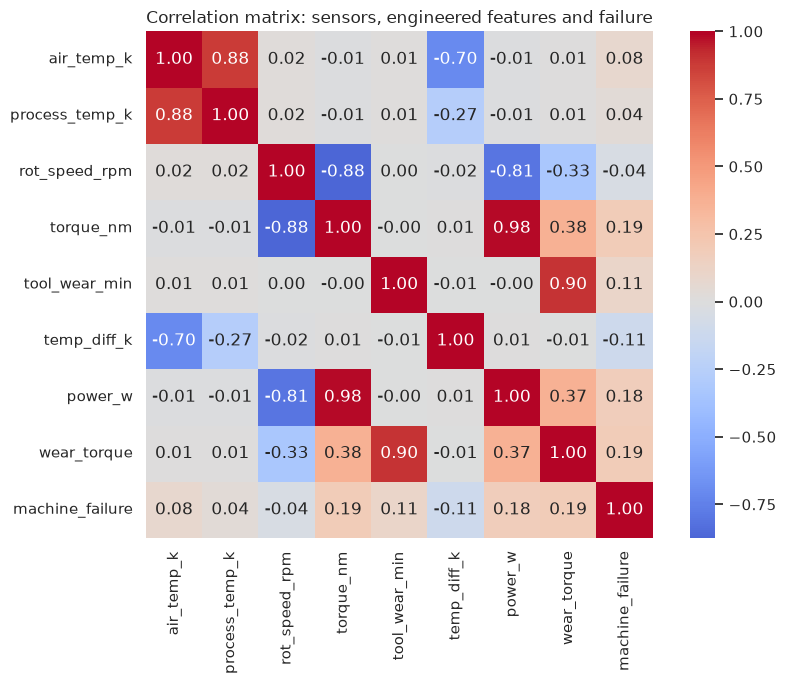

In [9]:
corr_cols = sensor_cols + new_feats + ["machine_failure"]
corr = df[corr_cols].corr()

print("Correlation with machine_failure:\n")
print(corr["machine_failure"].drop("machine_failure").sort_values(ascending=False).round(3).to_string())

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix: sensors, engineered features and failure")
plt.tight_layout()
plt.show()

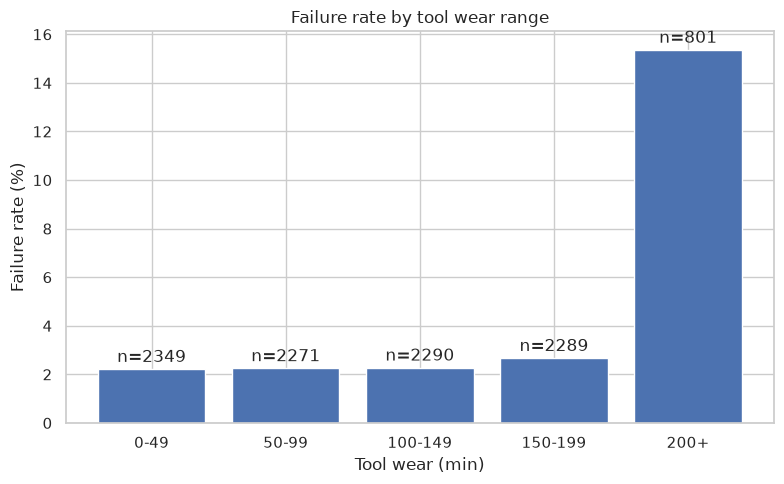

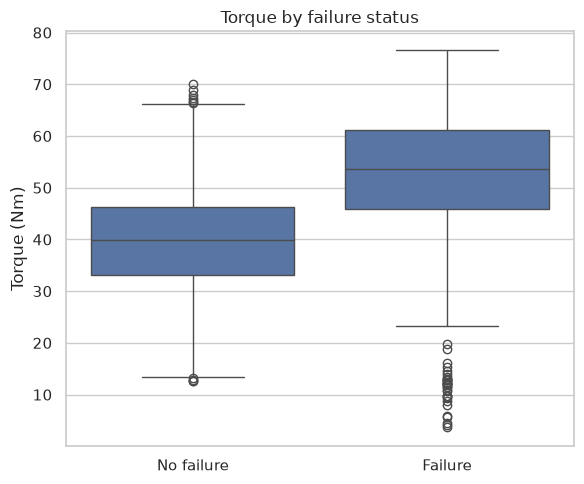

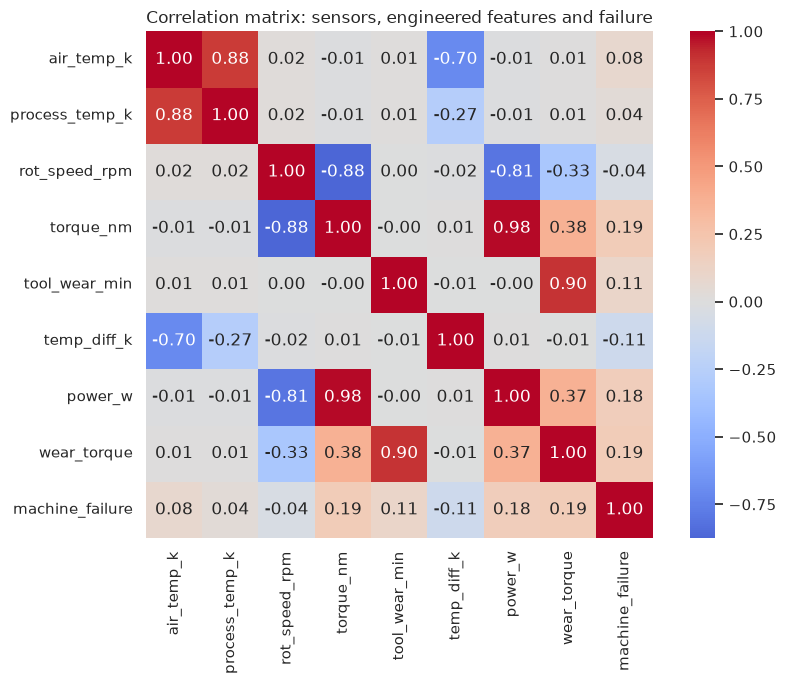

['correlation_matrix.png', 'failure_rate_by_tool_wear.png', 'torque_by_failure.png']


In [10]:
from pathlib import Path

fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

# Figure 1: failure rate by tool wear (the 2 records above 250 are merged into "200+")
wear_bin2 = pd.cut(
    df["tool_wear_min"],
    bins=[0, 50, 100, 150, 200, np.inf],
    right=False,
    labels=["0-49", "50-99", "100-149", "150-199", "200+"],
)
wear2 = df.groupby(wear_bin2, observed=True)["machine_failure"].agg(
    records="count", failure_rate="mean"
)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(wear2.index.astype(str), wear2["failure_rate"] * 100)
for bar, n in zip(bars, wear2["records"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f"n={n}", ha="center")
ax.set_title("Failure rate by tool wear range")
ax.set_xlabel("Tool wear (min)")
ax.set_ylabel("Failure rate (%)")
plt.tight_layout()
fig.savefig(fig_dir / "failure_rate_by_tool_wear.png", dpi=150)
plt.show()

# Figure 2: torque for normal records vs failures
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x="machine_failure", y="torque_nm", ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No failure", "Failure"])
ax.set_title("Torque by failure status")
ax.set_xlabel("")
ax.set_ylabel("Torque (Nm)")
plt.tight_layout()
fig.savefig(fig_dir / "torque_by_failure.png", dpi=150)
plt.show()

# Figure 3: correlation matrix
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Correlation matrix: sensors, engineered features and failure")
plt.tight_layout()
fig.savefig(fig_dir / "correlation_matrix.png", dpi=150)
plt.show()

print(sorted(p.name for p in fig_dir.iterdir()))

## Key observations

1. **Tool wear acts like a threshold, not a straight line.** The failure rate stays between 2.2% and 2.7% below 200 minutes of wear, then jumps to 15.1% in the 200-249 range (799 records, 121 failures).
2. **Torque is the strongest single signal, but every linear correlation with failure is weak.** The highest is 0.19 (`torque_nm`). The engineered features `wear_torque` (0.19) and `power_w` (0.18) did not beat torque alone, and they are strongly correlated with the sensors they were built from.
3. **The failure-mode columns leak the target.** 330 of the 339 failures have at least one mode flagged, so these columns are excluded from the model features. 27 records do not match: 18 have RNF flagged but no failure, and 9 are failures with no mode flagged.

*The dataset is synthetic, so these findings describe this dataset only and show correlation, not causation.*